# Druga Zadaća
Podaci koji ćemo analizirati učitani su iz biblioteke Seaborn.

### Palmer penguin dataset

Ovaj skup podataka sadrži biometrijske podatke o trima vrstama pingvina: Adelie, Gentoo i Chinstrap, s arhipelaga Palmer na Antarktici. 

Za svakog jedinku bilježi se otok na kojem je pronađena (`island`) duljina (`bill_length_mm`) i dubina (`bill_depth_mm`) kljuna u milimetrima, duljina peraje u milimetrima (`flipper_length_mm`), tjelesna masa u gramima (`body_mass_g`) te spol (`sex`). 

Istražit ćemo kako duljina peraje utječe na tjelesnu masu kod svih vrsta (regresijski dio zadatka), a zatim ćemo izraditi klasifikacijski model koji će na temelju unesenih podataka predviđati o kojoj se vrsti pingvina radi. Na kraju učitat ćemo još jedan skup podataka pogodan za klasteriranje i provesti algoritam KMeans.

#### *Učitavanje i pročišćavanje skupa podataka*

In [5]:
import pandas as pd # ucitavanje librarya pandas
import numpy as np # ucitavanje librarya numpy
import seaborn as sns # ucitavanje librarya seaborn

df = sns.load_dataset("penguins") # ucitavanje podataka u dataframe iz seaborn libraryja
df.head() # provjeravamo je li tablica dobro ucitana- ispis prvih 5 elemenata

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


In [6]:
df.tail() # ispis zadnjih 5 elemenata

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,Female
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,Male
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,Female
343,Gentoo,Biscoe,49.9,16.1,213.0,5400.0,Male


In [9]:
df.duplicated().sum() # broj dupliciranih vrijednosti

0

In [11]:
df.info() # informacije o data frameu

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


Nema dupliciranih vrijednosti, ali neke nedostaju (vidimo zbog različitog broja vrijednosti u pojedinim kolonama). Uočavamo da u 4. i 340. retku tablice gotovo sve vrijednosti nedostaju. Kada ih uklonimo, više nećemo imati nedostajućih numeričkih vrijednosti, već će jedine preostale nedostajuće vrijednosti biti one za spol. Budući da ih nema mnogo u odnosu na cijeli skup, i njih ćemo zanemariti.

In [14]:
df = df.dropna()

Sada je naš skup podataka potpun i spreman za daljnju analizu.

U sljedećem dijelu ove analize cilj nam je utvrditi postoji li povezanost između tjelesne mase i duljine peraje pingvina. To ćemo ispitati regresijom, pri čemu ćemo podatke podijeliti na testni i trening skup. Model ćemo validirati pomoću metrika RMSE i R², a zatim i metodom unakrsne validacije (cross-validation).

### *Motivacija za regresiju*

Vizualizirajmo točkastim dijagramom varijable tjelesna masa pingvina (u gramima) i duljina peraje (u milimetrima).

In [17]:
import matplotlib.pyplot as plt # matplotlib potreban za crtanje

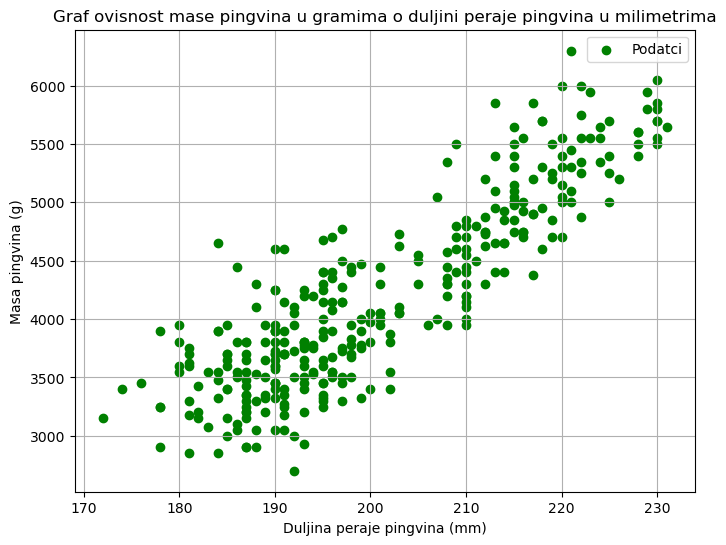

In [19]:
# Crtanje grafa

plt.figure(figsize=(8,6))  # velicina grafa
plt.scatter(df["flipper_length_mm"], df["body_mass_g"], color="green", label="Podatci")  # crtanje tocaka

# Oznake osi i naziv grafa
plt.xlabel("Duljina peraje pingvina (mm)") 
plt.ylabel("Masa pingvina (g)") 
plt.title("Graf ovisnost mase pingvina u gramima o duljini peraje pingvina u milimetrima") 

plt.legend() 
plt.grid(True)  
plt.show() 

Uočavamo lijep linearan regresijski uzorak, pa se spremamo za provođenje same regresije.

### *Provođenje regresije*

Prvo iz biblioteke sklearn učitavamo model linearne regresije: `LinearRegression()`, zatim metrike `r2_score` i `mean_squared_error`, te funkciju `train_test_split` za odvajanje skupa podataka na trening i testni dio.

In [22]:
from sklearn.linear_model import LinearRegression 

from sklearn.metrics import r2_score, mean_squared_error 

#Za razdvajanje skupa na testne i trening podatke
from sklearn.model_selection import train_test_split 

In [24]:
X = df['flipper_length_mm'].values.reshape(-1, 1)
Y = df['body_mass_g'].values

- `.values`: Ova metoda se koristi za pretvorbu Pandas stupca u NumPy polje. NumPy polja omogućavaju brze i efikasne operacije nad podacima, što je korisno za strojno učenje.
- `.reshape(-1, 1)`: Metoda `reshape` se koristi za mijenjanje oblika polja. U ovom slučaju, pretvaramo 1D polje u 2D polje s jednim stupcem. `-1` automatski određuje broj redaka na temelju veličine originalnog polja, dok `1` označava da želimo jednoznačni stupac. Ovaj oblik je potreban jer algoritmi strojnog učenja poput linearne regresije u scikit-learn očekuju ulazne podatke u 2D formatu.

- `df['body_mass_g'].values`:
- Ovdje također koristimo `.values` da bismo stupac 'body_mass_g' pretvorili u NumPy polje. Budući da se radi o vektoru odgovora (Y), koji je obično 1D polje, nije potrebno koristiti `.reshape()`.

In [27]:
# Odjeljivanje podataka na testni i validacijski skup
X_train, X_test, y_train, y_test = train_test_split( X, Y, random_state=104, test_size= 0.25, shuffle=True) 

In [29]:
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

Na kraju, model se uči nad podacima pomoću metode `fit`, gdje `X` predstavlja ulazne podatke (duljina peraje), a `Y` ciljane podatke (masa pingvina).

### *Grafički prikaz regresije*

In [32]:
X_plot = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)

- **`np.linspace(X.min(), X.max(), 100)`**: Ova funkcija stvara niz od 100 jednako razmaknutih točaka između minimalne i maksimalne vrijednosti u `X`. To nam omogućuje da generiramo glatku liniju za regresijski prikaz.
- **`.reshape(-1, 1)`**: Slično kao ranije, `reshape` se koristi za pretvaranje ovog polja u oblik stupca (2D polje). Ovo je potrebno jer funkcija `predict` očekuje 2D ulazne podatke. 

In [35]:
Y_plot = model.predict(X_plot)

Ova funkcija primjenjuje obučeni regresijski model na niz `X_plot`. Rezultat je niz predviđenih vrijednosti koje odgovaraju točkama u `X_plot`. Ove vrijednosti omogućuju crtanje regresijske linije na grafu.

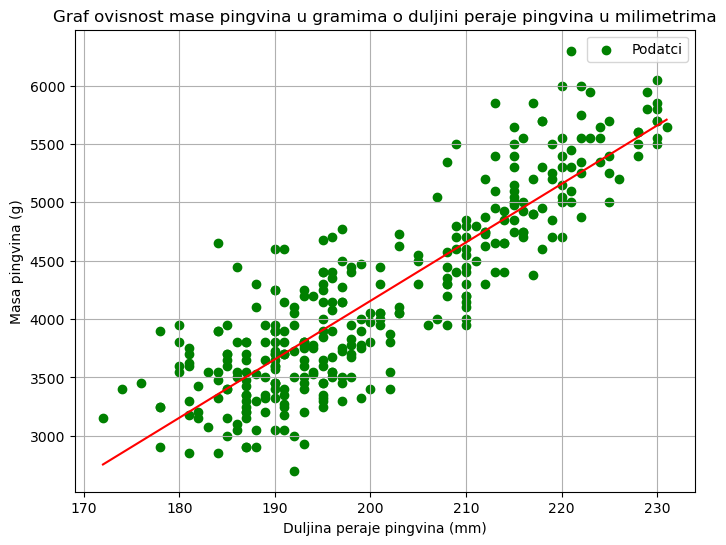

In [38]:
# Crtanje grafa

plt.figure(figsize=(8,6))  # velicina grafa
plt.scatter(df["flipper_length_mm"], df["body_mass_g"], color="green", label="Podatci")  # crtanje tocaka
plt.plot(X_plot, Y_plot, color="red", label= "") # crtanje pravca regresije

# Oznake osi i naziv grafa
plt.xlabel("Duljina peraje pingvina (mm)") 
plt.ylabel("Masa pingvina (g)") 
plt.title("Graf ovisnost mase pingvina u gramima o duljini peraje pingvina u milimetrima") 

plt.legend() 
plt.grid(True)  
plt.show() 

Dakle, utvrdili smo da duljina peraja pingvina i masa pingvina imaju lineranu povezanost.

### *Validacija regresije*

In [42]:
# R² i RMSE 
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("R²: ", r2)
print("RMSE: ", rmse)

R²:  0.6992498868846045
RMSE:  462.8852100725302


Uočavamo da regresijski pravac dobro opisuje podatke s približno 70% ukupne točnosti (prema R² metričkoj). Pretpostavljamo da razlog zašto taj broj nije i veći leži u činjenici da smo regresiju proveli nad cijelim skupom, dok omjeri mase i duljine peraje nisu nužno isti za svaku od triju vrsta pingvina.

In [45]:
from sklearn.model_selection import cross_val_score, cross_validate # Criss-cross validacija

In [47]:
cv_results = cross_validate(model, X, Y, cv=5, scoring=['r2', 'neg_root_mean_squared_error'])

print("Cross-Validated R²:", cv_results['test_r2'])
print("Prosječni R²:", np.mean(cv_results['test_r2']))

print("Cross-Validated RMSE:", -cv_results['test_neg_root_mean_squared_error'])
print("Prosječni RMSE:", -np.mean(cv_results['test_neg_root_mean_squared_error']))

Cross-Validated R²: [-0.16800546  0.25105037  0.06119012  0.64488982  0.5322434 ]
Prosječni R²: 0.264273651274498
Cross-Validated RMSE: [488.74428034 410.80252508 386.93593591 429.27905644 319.36369058]
Prosječni RMSE: 407.02509766975004


Rezultati unakrsne validacije (cross-validation) pokazuju znatno širu raspršenost i u prosjeku slabiju uspješnost u usporedbi s osnovnom R² metrikom na testnom skupu. To ukazuje na određenu nestabilnost modela kroz različite podjele podataka, što može biti posljedica razlika između vrsta pingvina koje nisu uzete u obzir u ovoj jednostavnoj regresiji.


### *Izgradnja klasifikacijskog modela*

Napravit ćemo stablo odlučivanja koje će na temelju numeričkih podataka i spola predvidjeti o kojoj se vrsti pingvina radi. Ovaj algoritam pogodan je za klasifikaciju jer je lako interpretirati njegove odluke i iz njega se mogu jasno iščitati najvažniji prediktori klasifikacije.

Prvo odvajamo naš DataFrame na značajke (X) i ciljne vrijednosti (y), koje zatim dijelimo na trening i testne podatke u omjeru 3:1.
Zatim uvozimo `DecisionTreeClassifier` kojim ćemo metodom `fit` na naše podatke primjeniti stablo odlučivanja.

In [51]:
X = df[['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']]
y = df["species"]

In [53]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

In [55]:
from sklearn.tree import DecisionTreeClassifier

In [57]:
model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

### *Vizualizacija stabla i tumačenje važnosti varijabli*

Vizualnim prikazom stabla u grafičkom obliku uočavamo algoritamski opisan tijek procesa klasifikacije što nam omogućuje da bolje razumijemo odluke koje model donosi pri razvrstavanju podataka. Nakon toga, izdvojit ćemo varijablu koja je imala najveći utjecaj na ishod klasifikacije, tj. koja se najčešće koristila u grananju stabla.

In [56]:
from sklearn.tree import plot_tree

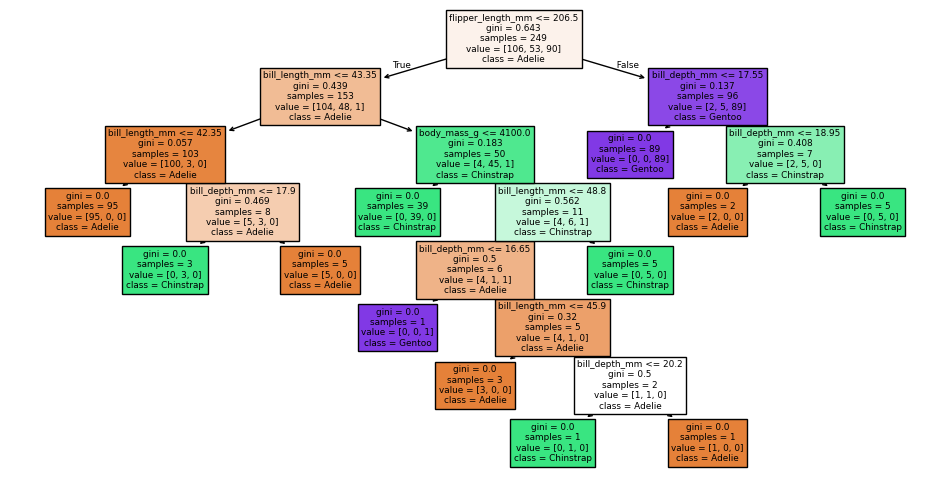

In [58]:
plt.figure(figsize=(12,6))
plot_tree(model, feature_names=X.columns, class_names=model.classes_, filled=True)
plt.show()

In [60]:
importances = model.feature_importances_ # dohvacanje vaznosti featurea

In [ ]:
# povezivanje s nazivima značajki

feature_importance = pd.Series(importances, index=X.columns)
najvazniji = feature_importance.sort_values(ascending=False)
print(najvazniji)

flipper_length_mm    0.497518
bill_length_mm       0.363064
bill_depth_mm        0.120811
body_mass_g          0.018606
dtype: float64


Najvažniji pokazatelji kod klasifikacije pingvina su duljina peraja i duljina kljuna pa  dubina kljuna. Kao najmanje važan je masa. Važnost je broj između 0 i 1 koji odražava koliko često i koliko učinkovito pojedina značajka razdvaja podatke u stablu. Što je veći broj, značajka ima veći doprinos u odlučivanju.

### *Validacija modela*

Točnost (`accuracy_score`) mjeri ukupan postotak ispravno klasificiranih primjera u odnosu na sve primjere.

`classification_report` daje detaljnu procjenu za svaku klasu:

- **Precision** – od svih primjera koji su predviđeni kao ta klasa, koliko ih je točno

- **Recall** – od svih stvarnih primjera te klase, koliko ih je model ispravno prepoznao

- **F1-score** – harmonijska sredina između precision i recall; koristan kada su klase neuravnotežene

- **Support** – broj stvarnih primjera te klase u testnom skupu

Ove metrike zajedno omogućuju dublju analizu uspješnosti klasifikacijskog modela.

In [65]:
from sklearn.metrics import classification_report, accuracy_score

y_pred = model.predict(X_test)
print("Točnost:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Točnost: 0.9761904761904762
              precision    recall  f1-score   support

      Adelie       0.97      0.97      0.97        40
   Chinstrap       0.93      0.93      0.93        15
      Gentoo       1.00      1.00      1.00        29

    accuracy                           0.98        84
   macro avg       0.97      0.97      0.97        84
weighted avg       0.98      0.98      0.98        84



Vidimo da je model koji smo izgradili vrlo precizan i s točnošću od 97% možemo biti izuzetno zadovoljni njegovom uspješnošću.

### *Klasteriranje*

Sljedeća stvar koju radimo je klasteriranje. Iz libraryja `pydataset` uvozimo dataset o uhićenjima u SAD-u (USArrests).

### USArrests dataset

Dataset sadrži podatke o broju uhićenja po 100.000 stanovnika u 50 američkih saveznih država za četiri vrste kaznenih djela: `Murder` (ubojstva), `Rape` (silovanja), `Assault` (napade) i `UrbanPop` (provale – postotak urbanog stanovništva). Svi podaci su numerički i odnose se na 1973. godinu.

In [ ]:
!pip install pydataset

In [97]:
from pydataset import data

df2 = data('USArrests')
df2.head()

,Murder,Assault,UrbanPop,Rape
Alabama,13.2,236,58,21.2
Alaska,10.0,263,48,44.5
Arizona,8.1,294,80,31.0
Arkansas,8.8,190,50,19.5
California,9.0,276,91,40.6


In [75]:
df2.describe()

,Murder,Assault,UrbanPop,Rape
count,50.00000,50.000000,50.000000,50.000000
mean,7.78800,170.760000,65.540000,21.232000
std,4.35551,83.337661,14.474763,9.366385
min,0.80000,45.000000,32.000000,7.300000
25%,4.07500,109.000000,54.500000,15.075000
50%,7.25000,159.000000,66.000000,20.100000
75%,11.25000,249.000000,77.750000,26.175000
max,17.40000,337.000000,91.000000,46.000000


### *Standardizacija*

Uočavamo da se u df2 naši podaci nalaze u različitim mjerilima. Kako ti nesrazmjeri ne bi utjecali na ishod KMeans algoritma (s obzirom na to da se minimizira euklidska udaljenost), podatke je potrebno standardizirati. U tu svrhu koristimo `StandardScaler()`, koji podatke centrira tako da imaju srednju vrijednost 0 i standardnu devijaciju 1. Ova transformacija omogućuje da sve varijable imaju jednak doprinos pri izračunu udaljenosti što je ključno za ispravno formiranje klastera.

In [77]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaled_data = scaler.fit_transform(df2) # fit_transform radi fitting (primjeni standardizacije) i tranform metodu vracanje skaliranih vrijednosti u dataframe

### *PCA*
Budući da naš skup podataka ima četiri varijable, ispitujemo mogućnost redukcije dimenzionalnosti pomoću metode glavnih komponenti (PCA). Osim što manji broj dimenzija može smanjiti rizik da KMeans algoritam pogrešno formira klastere (zbog tzv. prokletstva dimenzionalnosti), redukcija također omogućuje jednostavniju vizualizaciju podataka u dvije dimenzije, što nam dodatno pomaže u interpretaciji rezultata klasteriranja.

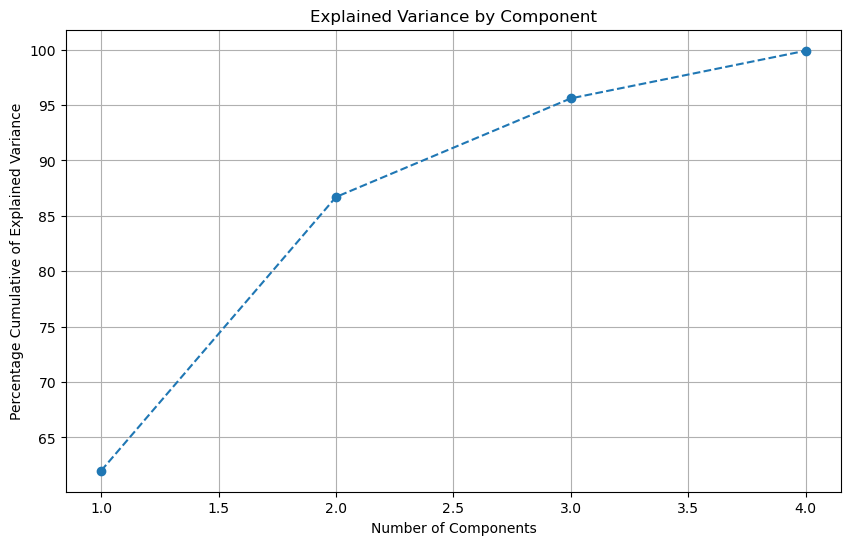

In [79]:
from sklearn.decomposition import PCA
pca = PCA()
principal_components = pca.fit_transform(scaled_data)
per_var = np.round(pca.explained_variance_ratio_*100, decimals = 1)

plt.figure(figsize = (10,6))
plt.plot(range(1, len(per_var)+1), per_var.cumsum(), marker = "o", linestyle = "--")
plt.grid()
plt.ylabel("Percentage Cumulative of Explained Variance")
plt.xlabel("Number of Components")
plt.title("Explained Variance by Component")
plt.show()

Vidimo da s dvije glavne komponente naš skup zadržava preko 85% ukupne varijance, odnosno informacija. Stoga ćemo podatke reducirati na dvodimenzionalni prostor, čime ne gubimo značajnu količinu informacija, a istovremeno dobivamo mogućnost vizualnog prikaza klastera u ravnini.

In [81]:
pca = PCA(n_components = 2)
pca.fit(scaled_data)
scores_pca = pca.transform(scaled_data)

### *KMeans*

Kako bismo odredili odgovarajući broj klastera za naš skup podataka, primjenjujemo metodu lakta. 

In [84]:
from sklearn.cluster import KMeans

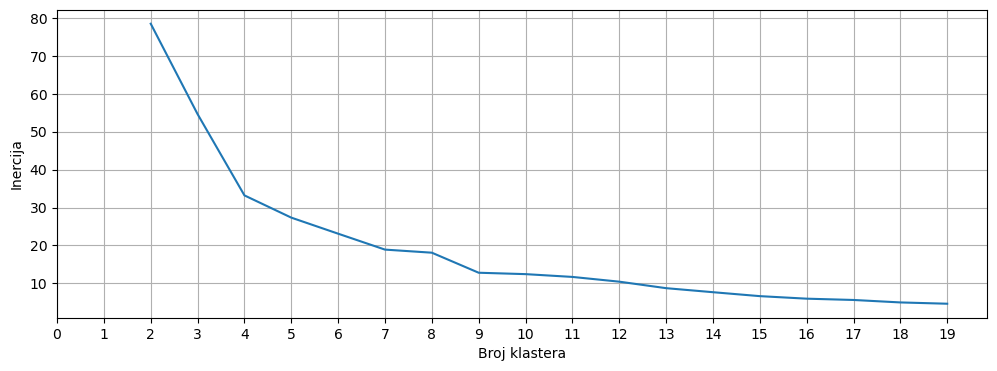

In [85]:
import warnings
warnings.filterwarnings("ignore")

inercija = []

for k in range(2, 20):
    kmeans = KMeans(random_state=0, n_clusters=k)
    kmeans.fit(scores_pca)
    inercija.append(kmeans.inertia_)

plt.figure(figsize=(12, 4))
plt.grid()
plt.plot(range(2, 20), inercija)
plt.xticks(range(0, 20))
plt.xlabel('Broj klastera')
plt.ylabel('Inercija')
plt.show()

Na temelju grafa inercije (unutargrupne varijance) u odnosu na broj klastera, uočavamo da se pri vrijednosti 4 pojavljuje tzv. "lakat" — najočitiji prijelom u liniji grafa. Ta točka označava trenutak nakon kojeg dodavanje novih klastera donosi sve manji dobitak u smislu smanjenja inercije, pa zaključujemo da je 4 optimalan broj klastera za ovaj skup.

In [87]:
kmeans = KMeans(n_clusters = 4)
kmeans.fit_transform(scores_pca)
centri = kmeans.cluster_centers_ # dohvacamo sredista klastera
labels = kmeans.labels_  # dodajemo boje po klasterima za vizualizaciju 

### *Vizualni prikaz klasteriranja*

In [158]:
boje = ['red', 'blue', 'green', 'yellow'] 

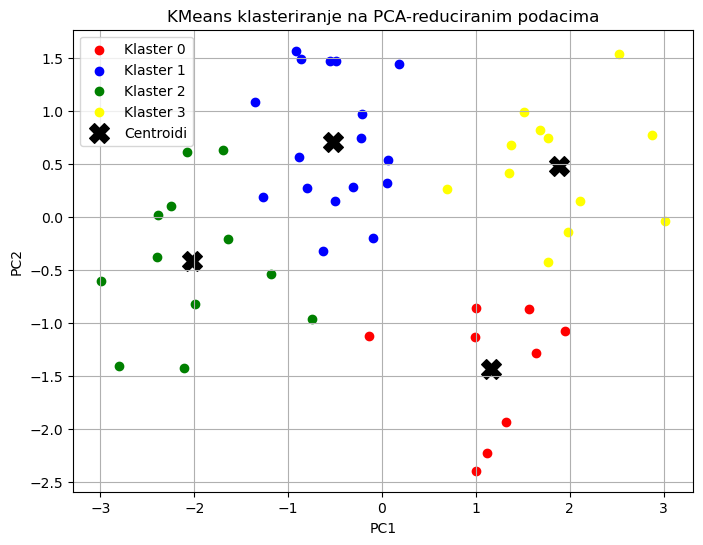

In [157]:
# Scatter plot s obojenim točkama po klasterima
plt.figure(figsize=(8,6))
for i in range(4):
    plt.scatter(scores_pca[labels == i, 0], scores_pca[labels == i, 1], 
                label=f"Klaster {i}", color=boje[i])

# Centroidi
plt.scatter(centri[:, 0], centri[:, 1], marker='X', s=200, color='black', label='Centroidi')

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("KMeans klasteriranje na PCA-reduciranim podacima")
plt.legend()
plt.grid(True)
plt.show()